# Previsão de inadimplência de cartão de crédito com MLP

Projeto de **Inteligência Artificial (UFRPE)**: uma rede neural MLP feita do zero com NumPy
(4 entradas → 8 neurônios ReLU → 1 saída sigmoide, erro MSE, backpropagation).

**Como usar este notebook:** execute as células **em ordem**, começando pela célula 1 (**Ctrl + Enter** em cada uma, ou *Ambiente de execução → Executar tudo*).

| Passo | O que faz |
|---|---|
| 1 | Prepara o projeto (envio dos arquivos) |
| 2 | Treina a rede e testa nos 30% restantes |
| 3 | Mostra a curva de aprendizado e a matriz de confusão |
| 4 | Roda as validações do código |
| 5 | Testa um cliente (você edita os valores) |
| 6 | Abre o menu completo da aplicação |

> **Importante:** se a sessão do Colab reiniciar ou desconectar, os arquivos enviados são apagados. Nesse caso, rode a célula 1 de novo.

## 1. Preparar o projeto

**Arquivos necessários:** `credito_mlp.zip` (o projeto) e `default_of_credit_card_clients.xls` (o banco de dados).
Rode a célula abaixo e selecione os dois arquivos na janela que abrir (pode escolher os dois de uma vez).

> Se o projeto estiver no GitHub, cole a URL na variável `URL_GITHUB` e o código é baixado de lá (o banco `.xls` ainda precisa ser enviado, se não estiver no repositório).

In [1]:
import glob, os, shutil, subprocess, sys, zipfile

URL_GITHUB = ""   # opcional. Ex.: "https://github.com/seu-usuario/seu-repositorio.git"

EM_COLAB = "google.colab" in sys.modules
BANCO = "default_of_credit_card_clients.xls"

def enviar(mensagem):
    """Abre a janela de envio de arquivos do Colab."""
    from google.colab import files
    print(mensagem)
    files.upload()

def achar_zip():
    zips = sorted(glob.glob("credito_mlp*.zip"))
    return zips[0] if zips else None

def achar_projeto(raiz):
    """Procura a pasta que contém o app.py (funciona qualquer que seja a estrutura do .zip)."""
    achados = glob.glob(os.path.join(raiz, "**", "app.py"), recursive=True)
    if not achados:
        raise FileNotFoundError("Não encontrei o app.py. O arquivo .zip enviado é mesmo o do projeto?")
    return os.path.dirname(os.path.abspath(achados[0]))

if not os.path.exists("app.py"):                          # ainda não estamos na pasta do projeto
    if URL_GITHUB:                                        # Opção B: baixar do GitHub
        subprocess.run(["git", "clone", URL_GITHUB, "projeto"], check=True)
    else:                                                 # Opção A: enviar o zip
        if achar_zip() is None and EM_COLAB:
            enviar(f"Selecione os arquivos: credito_mlp.zip e {BANCO}")
        if achar_zip() is None:
            raise FileNotFoundError("Envie o arquivo credito_mlp.zip para a pasta atual.")
        zipfile.ZipFile(achar_zip()).extractall("projeto")
    pasta = achar_projeto("projeto")
    if os.path.exists(BANCO):                             # banco enviado fora da pasta do projeto
        shutil.copy(BANCO, pasta)
    os.chdir(pasta)

if not os.path.exists(BANCO):                             # o banco precisa estar na pasta do projeto
    if EM_COLAB:
        enviar(f"Falta o banco de dados. Selecione o arquivo {BANCO}")
    if not os.path.exists(BANCO):
        raise FileNotFoundError(f"Coloque o arquivo {BANCO} na pasta {os.getcwd()}")

sys.path.insert(0, os.getcwd())
print("Pasta do projeto:", os.getcwd())
print("Arquivos:", sorted(os.listdir(".")))

Selecione os arquivos: credito_mlp.zip e default_of_credit_card_clients.xls


Saving credito_mlp.zip to credito_mlp.zip
Saving default_of_credit_card_clients.xls to default_of_credit_card_clients.xls
Pasta do projeto: /content/projeto/credito_mlp
Arquivos: ['.gitignore', 'README.md', 'app.py', 'avaliar_modelo.py', 'colab_credito_mlp.ipynb', 'curva_aprendizado.png', 'default_of_credit_card_clients.xls', 'mlp.py', 'modelo_mlp.npz', 'requirements.txt', 'treinamento.py', 'validacoes.py']


In [2]:
# Leitor de planilhas .xls/.xlsx (evita um aviso de descontinuação do pandas).
# Se esta célula der erro, pode ignorar: o projeto usa outro leitor automaticamente.
%pip install -q python-calamine

## 2. Treinar e testar a rede

O `treinamento.py` segue o protocolo:

1. **Divisão estratificada:** 70% de cada classe para treino e 30% de cada classe para teste.
2. **Oversampling** da classe minoritária (inadimplentes), **só no treino**, até igualar as duas classes.
3. **Treino** com backpropagation (100 épocas).
4. **Teste** nos 30% restantes, com a **matriz de confusão** (VP, FP, VN, FN).

In [3]:
import os; assert os.path.exists("treinamento.py"), "Projeto não preparado: execute primeiro a célula '1. Preparar o projeto'."
!python treinamento.py

Carregando dados...

Entradas da rede : PAY_0, PAY_MAX, LOG_LIMITE, LOG_PAGTO
Banco original   : 30000 clientes | inadimplentes: 22.1%
Treino (70%)     : 21000 clientes | classe 0: 16355 | classe 1: 4645
Treino balanceado: 32710 exemplos | classe 0: 16355 | classe 1: 16355  (oversampling da classe 1)
Teste (30%)      : 9000 clientes | classe 0: 7009 | classe 1: 1991  (inadimplentes: 22.1%)

Época   1 | MSE treino: 0.1994 | MSE treino original: 0.2015 | MSE teste: 0.1998
Época  10 | MSE treino: 0.1953 | MSE treino original: 0.1883 | MSE teste: 0.1868
Época  20 | MSE treino: 0.1948 | MSE treino original: 0.1882 | MSE teste: 0.1868
Época  30 | MSE treino: 0.1947 | MSE treino original: 0.1935 | MSE teste: 0.1922
Época  40 | MSE treino: 0.1944 | MSE treino original: 0.1864 | MSE teste: 0.1850
Época  50 | MSE treino: 0.1942 | MSE treino original: 0.1891 | MSE teste: 0.1879
Época  60 | MSE treino: 0.1940 | MSE treino original: 0.1920 | MSE teste: 0.1910
Época  70 | MSE treino: 0.1939 | MSE tr

## 3. Curva de aprendizado e matriz de confusão

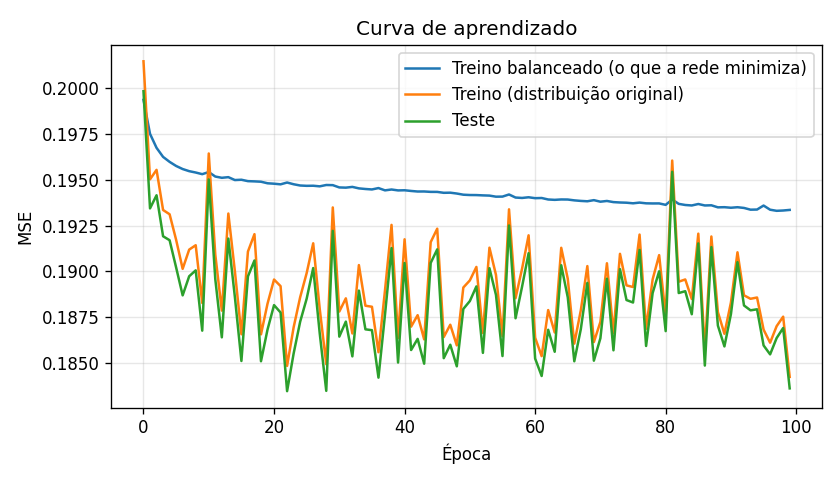

In [5]:
import os; assert os.path.exists("curva_aprendizado.png"), "Projeto não preparado: execute primeiro a célula '1. Preparar o projeto'."
from IPython.display import Image, display
display(Image("curva_aprendizado.png"))

In [ ]:
import glob, os, sys
if not os.path.exists("app.py"):          # ex.: a sessão reiniciou e o Colab voltou para /content
    achados = glob.glob("/content/**/app.py", recursive=True)
    if not achados:
        raise RuntimeError("O projeto não está preparado nesta sessão do Colab. Execute primeiro a célula "
                           "'1. Preparar o projeto' (os arquivos somem quando a sessão é reiniciada).")
    os.chdir(os.path.dirname(achados[0]))
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from mlp import MLP
from treinamento import ARQUIVO_MODELO, auc_roc, carregar_dados, dividir_estratificado, metricas

# Modelo salvo + os mesmos 30% de teste usados no treinamento
rede, params = MLP.carregar(ARQUIVO_MODELO)
X, y = carregar_dados()
_, teste = dividir_estratificado(y)
probs = rede.prever_proba((X[teste] - params["media"]) / params["desvio"])
m = metricas(y[teste], (probs >= float(params["limiar"])).astype(int))

matriz = np.array([[m["vn"], m["fp"]], [m["fn"], m["vp"]]])
nomes = [["VN", "FP"], ["FN", "VP"]]
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(matriz, cmap="Blues")
ax.set_xticks([0, 1], ["Previsto: paga", "Previsto: calote"])
ax.set_yticks([0, 1], ["Real: paga", "Real: calote"])
for i in range(2):
    for j in range(2):
        cor = "white" if matriz[i, j] > matriz.max() / 2 else "black"
        ax.text(j, i, f"{nomes[i][j]}\n{matriz[i, j]}", ha="center", va="center", color=cor, fontsize=13)
ax.set_title(f"Matriz de confusão (teste: {len(teste)} clientes)")
plt.tight_layout()
plt.show()

print(f"Acurácia {m['acuracia']:.1%} | Precisão {m['precisao']:.1%} | Recall {m['recall']:.1%} | "
      f"F1 {m['f1']:.3f} | AUC {auc_roc(probs, y[teste]):.3f}")

**Como ler a matriz:**
- **VP:** previu calote e deu calote.  **VN:** previu que pagaria e pagou.
- **FP:** previu calote, mas o cliente pagou (alarme falso).  **FN:** previu que pagaria, mas deu calote (o erro mais caro para um banco).

## 4. Validações do código

Roda 19 testes que comprovam o funcionamento: verificação numérica do backpropagation, XOR, divisão estratificada,
oversampling sem vazamento, importação do banco, reprodutibilidade etc. Leva cerca de 20 a 30 segundos.

In [4]:
import os; assert os.path.exists("validacoes.py"), "Projeto não preparado: execute primeiro a célula '1. Preparar o projeto'."
!python validacoes.py


--- A) A rede neural ---
[OK] Backpropagation confere com o gradiente numérico (W1, b1, W2, b2)  ->  erro relativo máximo = 1.10e-09
[OK] Saída da rede sempre entre 0 e 1, com formato (n, 1)  ->  mín=0.0000 máx=1.0000
[OK] Rede aprende o XOR (não linear) com ReLU + sigmoide + MSE  ->  MSE 0.261 -> 0.0001 | acertos 4/4
[OK] Métricas (acurácia/precisão/recall/F1/matriz) e AUC corretas em casos conhecidos

--- B) Os dados ---
[OK] Banco íntegro: 30.000 linhas, IDs únicos, sem nulos, alvo binário, pagamentos não negativos  ->  inadimplentes=22.1% | PAY de -2 a 8 | limite de 10,000 a 1,000,000
[OK] Divisão estratificada: 70% da classe 0 + 70% da classe 1 no treino; 30% de cada no teste  ->  treino 21000 (classe 0: 16355, classe 1: 4645) | teste 9000 (classe 0: 7009, classe 1: 1991)
[OK] Treino e teste mantêm a mesma proporção de inadimplentes do banco  ->  banco 22.12% | treino 22.12% | teste 22.12%
[OK] Oversampling iguala as duas classes no treino  ->  classe 0: 16355 | classe 1: 16355
[

## 5. Testar um cliente

Edite os valores e rode a célula. O histórico tem 6 meses, **do mais recente (primeiro) para o mais antigo (último)**:

`-2` = não usou o cartão · `-1` = pagou a fatura inteira · `0` = pagou só o mínimo · `1` a `9` = meses de atraso

In [6]:
import glob, os, sys
if not os.path.exists("app.py"):          # ex.: a sessão reiniciou e o Colab voltou para /content
    achados = glob.glob("/content/**/app.py", recursive=True)
    if not achados:
        raise RuntimeError("O projeto não está preparado nesta sessão do Colab. Execute primeiro a célula "
                           "'1. Preparar o projeto' (os arquivos somem quando a sessão é reiniciada).")
    os.chdir(os.path.dirname(achados[0]))
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

import app
from mlp import MLP
from treinamento import ARQUIVO_MODELO

limite = 20000                      # limite do cartão (NT$); no banco, vai de 10.000 a 1.000.000
historico = [0, 0, 0, 0, 1, 2]      # situação de pagamento: do mês mais recente ao mais antigo
ultimo_pagamento = 1550             # valor pago na última fatura (NT$)

rede, params = MLP.carregar(ARQUIVO_MODELO)
risco, alto_risco = app.prever_cliente(rede, params, historico, limite, ultimo_pagamento)

print(f"Pontuação de risco: {risco:.1%}  (alto risco a partir de 50%)")
print("Previsão:", "ALTO RISCO" if alto_risco else "BAIXO RISCO")
print("Obs.: a pontuação serve para ordenar clientes por risco; não é a probabilidade real de calote.")

Pontuação de risco: 64.8%  (alto risco a partir de 50%)
Previsão: ALTO RISCO
Obs.: a pontuação serve para ordenar clientes por risco; não é a probabilidade real de calote.


## 6. Aplicação completa (menu)

O menu permite **cadastrar clientes**, **importar o banco inteiro (30.000 clientes)**, ver o relatório de acurácia e exportar os resultados em CSV.
Digite as opções no campo que aparece **logo abaixo da célula** e aperte Enter. Para sair, digite `0`.

> Dica para a apresentação: use a opção **3** para importar o banco completo e a **4** para ver o relatório.

In [7]:
import glob, os, sys
if not os.path.exists("app.py"):          # ex.: a sessão reiniciou e o Colab voltou para /content
    achados = glob.glob("/content/**/app.py", recursive=True)
    if not achados:
        raise RuntimeError("O projeto não está preparado nesta sessão do Colab. Execute primeiro a célula "
                           "'1. Preparar o projeto' (os arquivos somem quando a sessão é reiniciada).")
    os.chdir(os.path.dirname(achados[0]))
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

import app
app.main()


===== ANÁLISE DE CRÉDITO (MLP) =====
1) Cadastrar cliente e analisar risco
2) Listar clientes cadastrados
3) Importar banco de dados completo
4) Relatório de acurácia
5) Exportar resultados (CSV)
0) Sair
Opção: 0
